In [21]:
# imports
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

Text(0, 0.5, 'Angle (rad)')

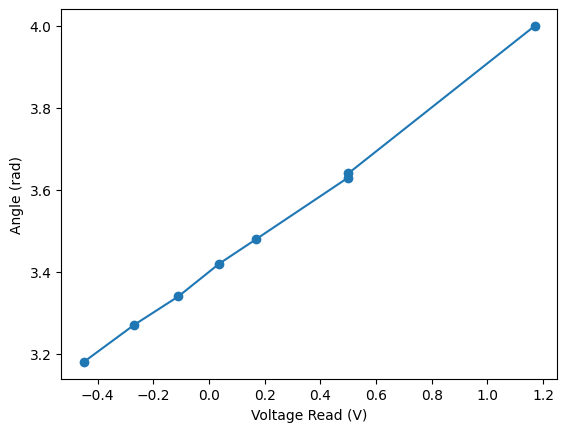

In [22]:
voltages_inputted = [2, 3, 4, 5, 6]
voltages_read = [-0.45, -0.27, -0.11, 0.037, 0.17, 0.5, 0.5, 1.17]
angles = [3.18, 3.27, 3.34, 3.42, 3.48, 3.63, 3.64, 4]
# plot angles vs voltage
plt.plot(voltages_read, angles, marker='o')
#Label axes
plt.xlabel('Voltage Read (V)')
plt.ylabel('Angle (rad)')



angle = (0.501 ± 0.008) * V + (3.398 ± 0.004)
Residual std dev: 0.0116 rad
Points within ±1σ: 6/8


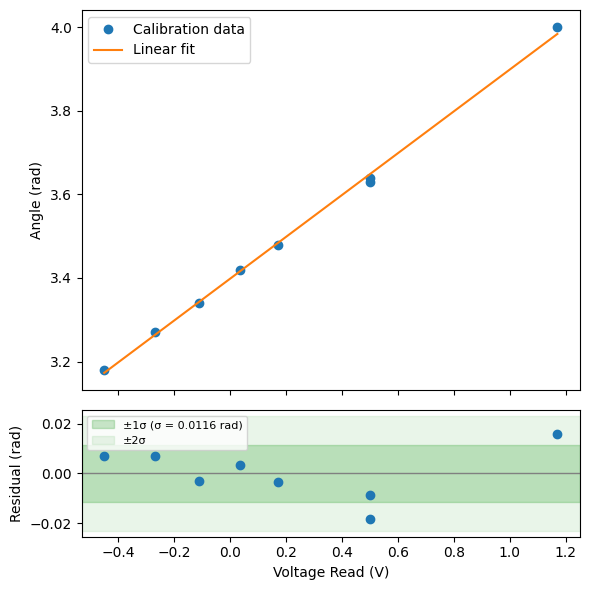

In [24]:
# Linearization made with Claude

voltages_read = np.array([-0.45, -0.27, -0.11, 0.037, 0.17, 0.5, 0.5, 1.17])
angles = np.array([3.18, 3.27, 3.34, 3.42, 3.48, 3.63, 3.64, 4])

# Linear fit: angle = slope * V + intercept
coeffs, cov = np.polyfit(voltages_read, angles, 1, cov=True)
slope, intercept = coeffs
slope_err, intercept_err = np.sqrt(np.diag(cov))
print(f"angle = ({slope:.3f} ± {slope_err:.3f}) * V + ({intercept:.3f} ± {intercept_err:.3f})")

def voltage_to_angle(v):
    return slope * np.asarray(v) + intercept

# Residuals and their standard deviation
residuals = angles - voltage_to_angle(voltages_read)
# ddof=2 because the fit used 2 parameters (slope and intercept)
sigma = np.std(residuals, ddof=2)
print(f"Residual std dev: {sigma:.4f} rad")
print(f"Points within ±1σ: {np.sum(np.abs(residuals) <= sigma)}/{len(residuals)}")

# Plot
v_line = np.linspace(voltages_read.min(), voltages_read.max(), 200)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(voltages_read, angles, 'o', label='Calibration data')
ax1.plot(v_line, voltage_to_angle(v_line), '-', label='Linear fit')
ax1.set_ylabel('Angle (rad)')
ax1.legend()

ax2.axhline(0, color='gray', lw=1)
ax2.axhspan(-sigma, sigma, color='C2', alpha=0.25, label=f'±1σ (σ = {sigma:.4f} rad)')
ax2.axhspan(-2*sigma, 2*sigma, color='C2', alpha=0.10, label='±2σ')
ax2.plot(voltages_read, residuals, 'o', color='C0')
ax2.set_xlabel('Voltage Read (V)')
ax2.set_ylabel('Residual (rad)')
ax2.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

In [27]:
# Data cleanup with Claude
import re

# Calibration (from the linear fit)
slope, intercept = 0.50069725, 3.39817767

# Load the original wide-format data
df = pd.read_csv('lab5data.csv')

def run_number(col):
    return int(re.search(r'#(\d+)', col).group(1))

# Keep runs 1-21 and the last run
last_run = max(run_number(c) for c in df.columns)
keep = set(range(1, 22)) | {last_run}
df = df[[c for c in df.columns if run_number(c) in keep]]

# Convert voltages to angles (rad), keeping the time/angle column order
df_angles = pd.DataFrame()
for col in df.columns:
    if col.startswith('Voltage (V)'):
        df_angles[col.replace('Voltage (V)', 'Angle (rad)')] = slope * df[col] + intercept
    else:
        df_angles[col] = df[col]

df_angles.to_csv('lab5data_angles.csv', index=False)

In [ ]:
# Trim data, done with Claude

threshold = 0.02      # rad: deviation from rest angle that counts as "oscillations started"
n_baseline = 25       # samples (0.5 s) used to estimate the rest angle
pre_samples = 5       # samples to keep just before the detected onset

df_angles = pd.read_csv('lab5data_angles.csv')

trimmed = {}
onsets = {}
for col in df_angles.columns:
    if not col.startswith('Angle (rad)'):
        continue
    run = col.split('#')[1]
    time_col = f'Time (s) Run #{run}'
    run_df = df_angles[[time_col, col]].dropna()
    angle = run_df[col].to_numpy()

    baseline = np.median(angle[:n_baseline])
    moved = np.abs(angle - baseline) > threshold
    onset = int(np.argmax(moved))           # first sample past the threshold
    if not moved.any():
        print(f'Run #{run}: no oscillation detected, keeping all data')
        onset = 0
    start = max(onset - pre_samples, 0)

    run_df = run_df.iloc[start:].reset_index(drop=True)
    run_df[time_col] = run_df[time_col] - run_df[time_col].iloc[0]   # restart time at 0
    trimmed[time_col] = run_df[time_col]
    trimmed[col] = run_df[col]
    onsets[run] = round(df_angles[time_col].iloc[onset], 2)

df_trimmed = pd.DataFrame(trimmed)          # shorter runs are padded with NaN
df_trimmed.to_csv('lab5data_angles_trimmed.csv', index=False)
print('Onset times (s):', onsets)

Onset times (s): {'1': np.float64(0.76), '2': np.float64(0.82), '3': np.float64(0.96), '4': np.float64(2.18), '5': np.float64(0.56), '6': np.float64(1.6), '7': np.float64(1.5), '8': np.float64(0.7), '9': np.float64(1.78), '10': np.float64(1.72), '11': np.float64(1.34), '12': np.float64(1.22), '13': np.float64(1.3), '14': np.float64(1.22), '15': np.float64(1.08), '16': np.float64(1.1), '17': np.float64(1.32), '18': np.float64(1.58), '19': np.float64(1.18), '20': np.float64(1.08), '21': np.float64(1.44), '33': np.float64(1.7)}


<Axes: xlabel='Time (s) Run #1'>

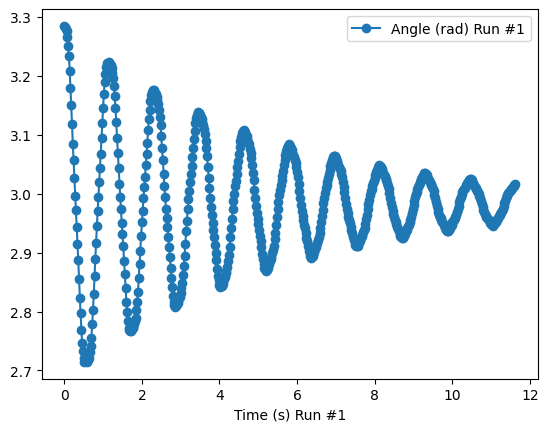

In [29]:
# Plot some of the data of the dataframe

# Plot run 1 from the dataframe
df_trimmed.plot(x='Time (s) Run #1', y='Angle (rad) Run #1', marker='o')

In [ ]:
# Extract peaks and periods, done with Claude
from scipy.signal import find_peaks

df_trimmed = pd.read_csv('lab5data_angles_trimmed.csv')

prominence = 0.01   # rad: minimum height of a peak above its surroundings
half_window = 5     # samples on each side used for the parabola fit (5 -> +-0.1 s)
min_separation = 0.5  # s: peaks closer than this are duplicates (use ~half the expected period)

peak_rows = []      # one row per peak: run, peak number, time, angle
period_rows = []    # one row per run: mean period and its uncertainty

for col in df_trimmed.columns:
    if not col.startswith('Angle (rad)'):
        continue
    run = int(col.split('#')[1])
    time_col = f'Time (s) Run #{run}'
    run_df = df_trimmed[[time_col, col]].dropna()
    t = run_df[time_col].to_numpy()
    a = run_df[col].to_numpy()

    dt = np.median(np.diff(t))
    idx, _ = find_peaks(a, prominence=prominence, distance=max(int(min_separation / dt), 1))
    # Drop peaks too close to the edges for a full fit window
    idx = idx[(idx >= half_window) & (idx < len(a) - half_window)]

    t_peaks, a_peaks = [], []
    for i in idx:
        sl = slice(i - half_window, i + half_window + 1)
        c2, c1, c0 = np.polyfit(t[sl] - t[i], a[sl], 2)   # a = c2*x^2 + c1*x + c0
        x_max = -c1 / (2 * c2)                            # vertex of the parabola
        t_peaks.append(t[i] + x_max)
        a_peaks.append(c0 - c1**2 / (4 * c2))

    t_peaks, a_peaks = np.array(t_peaks), np.array(a_peaks)
    for k, (tp, ap) in enumerate(zip(t_peaks, a_peaks), start=1):
        peak_rows.append({'Run': run, 'Peak #': k, 'Time (s)': tp, 'Angle (rad)': ap})

    periods = np.diff(t_peaks)
    period_rows.append({
        'Run': run,
        'N peaks': len(t_peaks),
        'Mean period (s)': periods.mean() if len(periods) else np.nan,
        'Std of period (s)': periods.std(ddof=1) if len(periods) > 1 else np.nan,
        'Std error (s)': periods.std(ddof=1) / np.sqrt(len(periods)) if len(periods) > 1 else np.nan,
    })

df_peaks = pd.DataFrame(peak_rows)
df_periods = pd.DataFrame(period_rows)
df_peaks.to_csv('lab5_peaks.csv', index=False)
df_periods.to_csv('lab5_periods.csv', index=False)
print(df_periods.round(4).to_string(index=False))

 Run  N peaks  Mean period (s)  Std of period (s)  Std error (s)
   1        9           1.1640             0.0049         0.0017
   2       10           1.1643             0.0013         0.0004
   3        9           1.1626             0.0028         0.0010
   4        7           1.1641             0.0039         0.0016
   5        7           1.1641             0.0030         0.0012
   6        6           1.1595             0.0030         0.0013
   7        5           1.1580             0.0143         0.0071
   8        4           1.1649             0.0139         0.0080
   9        5           1.1647             0.0131         0.0066
  10        2           1.2134                NaN            NaN
  11        2           1.1905                NaN            NaN
  12        2           1.2016                NaN            NaN
  13        3           1.1713             0.0064         0.0045
  14        3           1.1691             0.0093         0.0066
  15        3           1

 Run  N maxima  N minima  Period (s)  Period err (s)  omega_d (rad/s)  omega_d err (rad/s)  theta_eq (rad)  A_up (rad)  A_down (rad)  gamma (1/s)  gamma err (1/s)  Envelope RMS resid (rad)  omega_0 (rad/s)
   1         9        10      1.1642          0.0005           5.3970               0.0022          2.9829      0.2998        0.3007       0.1890           0.0005                    0.0006           5.4003
   2        10        10      1.1645          0.0001           5.3957               0.0006          2.9833      0.3018        0.3048       0.1939           0.0004                    0.0004           5.3991
   3         9        10      1.1626          0.0003           5.4043               0.0014          2.9833      0.3001        0.3019       0.1927           0.0003                    0.0003           5.4077
   4         7         7      1.1639          0.0003           5.3982               0.0014          2.9835      0.3020        0.3045       0.3622           0.0006              

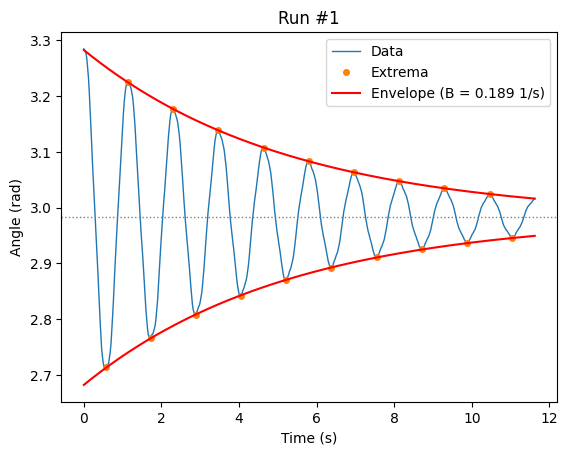

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

df_trimmed = pd.read_csv('lab5data_angles_trimmed.csv')

prominence = 0.01     # rad: minimum prominence of an extremum
half_window = 5       # samples on each side for the parabola refinement
min_separation = 0.5  # s: extrema closer than this are duplicates

def refined_extrema(t, a, sign):
    """Times and values of the maxima (sign=+1) or minima (sign=-1) of a(t),
    refined with a parabola fit around each extremum."""
    dt = np.median(np.diff(t))
    idx, _ = find_peaks(sign * a, prominence=prominence,
                        distance=max(int(min_separation / dt), 1))
    idx = idx[(idx >= half_window) & (idx < len(a) - half_window)]
    t_ext, a_ext = [], []
    for i in idx:
        sl = slice(i - half_window, i + half_window + 1)
        c2, c1, c0 = np.polyfit(t[sl] - t[i], a[sl], 2)
        t_ext.append(t[i] - c1 / (2 * c2))
        a_ext.append(c0 - c1**2 / (4 * c2))
    return np.array(t_ext), np.array(a_ext)

# Envelope model: maxima follow  theta_eq + A_up * exp(-gamma t)
#                 minima follow  theta_eq - A_down * exp(-gamma t)
def envelope(X, theta_eq, A_up, A_down, gamma):
    t, is_max = X
    return theta_eq + np.where(is_max, A_up, -A_down) * np.exp(-gamma * t)

results = []
envelopes = {}   # kept so we can plot the fits afterwards
run_data = {}
for col in df_trimmed.columns:
    if not col.startswith('Angle (rad)'):
        continue
    run = int(col.split('#')[1])
    time_col = f'Time (s) Run #{run}'
    run_df = df_trimmed[[time_col, col]].dropna()
    t, a = run_df[time_col].to_numpy(), run_df[col].to_numpy()
    run_data[run] = (t, a)

    t_max, a_max = refined_extrema(t, a, +1)
    t_min, a_min = refined_extrema(t, a, -1)

    # --- Angular frequency: consecutive extrema (max and min) are half a period apart,
    #     so fit  t_extremum = t0 + m * T/2  using all of them (m = extremum number)
    row = {'Run': run, 'N maxima': len(t_max), 'N minima': len(t_min)}
    t_all = np.sort(np.concatenate([t_max, t_min]))
    if len(t_all) >= 3:
        half_guess = np.median(np.diff(t_all))
        m = np.round((t_all - t_all[0]) / half_guess)       # robust to a missed extremum
        (half_T, t0), cov = np.polyfit(m, t_all, 1, cov=True)
        T, sigma_T = 2 * half_T, 2 * np.sqrt(cov[0, 0])
    elif len(t_all) == 2:
        T, sigma_T = 2 * np.diff(t_all)[0], np.nan
    else:
        T, sigma_T = np.nan, np.nan
    omega = 2 * np.pi / T
    row.update({'Period (s)': T, 'Period err (s)': sigma_T,
                'omega_d (rad/s)': omega, 'omega_d err (rad/s)': 2 * np.pi * sigma_T / T**2})

    # --- Envelope fit on maxima and minima together
    X = (np.concatenate([t_max, t_min]),
         np.concatenate([np.ones(len(t_max), bool), np.zeros(len(t_min), bool)]))
    y = np.concatenate([a_max, a_min])
    if len(y) >= 5:
        p0 = [np.mean(a[-20:]), a_max[0] - np.mean(a[-20:]), np.mean(a[-20:]) - a_min[0], 0.2]
        try:
            popt, pcov = curve_fit(envelope, X, y, p0=p0)
            perr = np.sqrt(np.diag(pcov))
            resid = y - envelope(X, *popt)
            row.update({'theta_eq (rad)': popt[0], 'A_up (rad)': popt[1], 'A_down (rad)': popt[2],
                        'gamma (1/s)': popt[3], 'gamma err (1/s)': perr[3],
                        'Envelope RMS resid (rad)': np.sqrt(np.mean(resid**2))})
            envelopes[run] = (X, y, popt)
        except RuntimeError:
            print(f'Run #{run}: envelope fit did not converge')
    else:
        print(f'Run #{run}: only {len(y)} extrema, skipping envelope fit')
    results.append(row)

df_results = pd.DataFrame(results)
# Undamped natural frequency (assumes viscous damping): omega_0^2 = omega_d^2 + gamma^2
df_results['omega_0 (rad/s)'] = np.sqrt(df_results['omega_d (rad/s)']**2 + df_results['gamma (1/s)']**2)
df_results.to_csv('lab5_omega_gamma.csv', index=False)
print(df_results.round(4).to_string(index=False))

# ---- Check the envelope fit visually for one run (change `run` to look at others)
run = 1
t, a = run_data[run]
(t_ext, is_max), y, (theta_eq, A_up, A_down, gamma) = envelopes[run]
t_line = np.linspace(0, t.max(), 500)
plt.plot(t, a, lw=1, label='Data')
plt.plot(t_ext, y, 'o', ms=4, label='Extrema')
plt.plot(t_line, theta_eq + A_up * np.exp(-gamma * t_line), 'r-', label=f'Envelope (B = {gamma:.3f} 1/s)')
plt.plot(t_line, theta_eq - A_down * np.exp(-gamma * t_line), 'r-')
plt.axhline(theta_eq, color='gray', ls=':', lw=1)
plt.xlabel('Time (s)'); plt.ylabel('Angle (rad)'); plt.title(f'Run #{run}')
plt.legend(); plt.show()

In [32]:
# Run this AFTER the previous block (uses df_trimmed, df_results, refined_extrema, envelope)
res = df_results.set_index('Run')
rows = []
for col in df_trimmed.columns:
    if not col.startswith('Angle (rad)'):
        continue
    run = int(col.split('#')[1])
    time_col = f'Time (s) Run #{run}'
    d = df_trimmed[[time_col, col]].dropna()
    t, a = d[time_col].to_numpy(), d[col].to_numpy()

    t_max, a_max = refined_extrema(t, a, +1)
    t_min, a_min = refined_extrema(t, a, -1)
    te = np.concatenate([t_max, t_min]); ae = np.concatenate([a_max, a_min])
    sgn = np.concatenate([np.ones(len(t_max)), -np.ones(len(t_min))])
    o = np.argsort(te); te, ae, sgn = te[o], ae[o], sgn[o]
    theta_eq, gamma = res.loc[run, 'theta_eq (rad)'], res.loc[run, 'gamma (1/s)']
    row = {'Run': run, 'N extrema': len(te)}

    # 1) Period stability: half-periods vs time, and first half vs second half of the run
    half_periods = np.diff(te)
    if len(half_periods) >= 4:
        t_mid = 0.5 * (te[1:] + te[:-1])
        row['Half-period drift (ms/s)'] = 1e3 * np.polyfit(t_mid, half_periods, 1)[0]
        row['Half-period std (ms)'] = 1e3 * half_periods.std(ddof=1)
        h = len(half_periods) // 2
        row['T first half (s)'] = 2 * half_periods[:h].mean()
        row['T second half (s)'] = 2 * half_periods[h:].mean()

    # 2) Decay stability: local rate between consecutive same-side extrema (one period apart)
    amp = np.abs(ae - theta_eq)
    local = []
    for side in (+1, -1):
        m = (sgn == side) & (amp > 0.03)       # skip extrema near the noise floor
        tt, aa = te[m], amp[m]
        if len(tt) >= 2:
            local += list(np.log(aa[:-1] / aa[1:]) / np.diff(tt))
    if len(local) >= 3:
        row['Local gamma min'], row['Local gamma max'] = min(local), max(local)

    # 3) Refit gamma separately on the first and second half of the extrema
    for name, sel in (('first', slice(0, len(te) // 2)), ('second', slice(len(te) // 2, None))):
        if len(te[sel]) >= 5:
            try:
                p, _ = curve_fit(envelope, (te[sel], sgn[sel] > 0), ae[sel],
                                 p0=[theta_eq, 0.3, 0.3, gamma])
                row[f'gamma {name} half'] = p[3]
            except RuntimeError:
                pass

    # 4) Sensitivity of gamma to theta_eq: fix it at +-0.005 rad and refit
    for dth in (-0.005, 0.005):
        f = lambda X, A1, A2, gm: envelope(X, theta_eq + dth, A1, A2, gm)
        try:
            p, _ = curve_fit(f, (te, sgn > 0), ae, p0=[0.3, 0.3, gamma])
            row[f'gamma (theta_eq {dth:+.3f})'] = p[2]
        except RuntimeError:
            pass
    rows.append(row)

df_checks = pd.DataFrame(rows)
df_checks.to_csv('lab5_stability_checks.csv', index=False)
print(df_checks.round(4).to_string(index=False))

 Run  N extrema  Half-period drift (ms/s)  Half-period std (ms)  T first half (s)  T second half (s)  Local gamma min  Local gamma max  gamma first half  gamma second half  gamma (theta_eq -0.005)  gamma (theta_eq +0.005)
   1         19                    0.5963                3.4042            1.1611             1.1672           0.1817           0.1975            0.1882             0.1922                   0.1899                   0.1877
   2         20                    0.1581                1.1977            1.1632             1.1652           0.1871           0.2029            0.1926             0.1987                   0.1941                   0.1931
   3         19                    0.3925                1.9285            1.1603             1.1650           0.1846           0.1956            0.1938             0.1925                   0.1936                   0.1913
   4         14                    0.2692                2.6397            1.1630             1.1660           0

In [33]:
# Run this AFTER the previous blocks (uses df_trimmed, df_results, df_checks, refined_extrema)
N = 1              # number of complete cycles separating the two amplitudes in the log decrement
amp_min = 0.02     # rad: ignore amplitudes below this (too close to the noise floor)

def Q_from_BC(B, C):
    return np.sqrt(B**2 + C**2) / (2 * B)

def Q_from_delta(delta):
    return 0.5 * np.sqrt(1 + (2 * np.pi / delta)**2)

def fmt(value, err=np.nan):
    """Format value ± err: error to 1 significant figure (2 if its leading digit is 1)."""
    if not np.isfinite(value):
        return '---'
    if not np.isfinite(err) or err <= 0:
        return f'{value:.2f}'
    exp = int(np.floor(np.log10(err)))
    lead = int(err / 10**exp)
    dec = max(0, -exp + (1 if lead == 1 else 0))
    return f'${value:.{dec}f} \\pm {err:.{dec}f}$'

res = df_results.set_index('Run')
chk = df_checks.set_index('Run')
table_rows = []
for col in df_trimmed.columns:
    if not col.startswith('Angle (rad)'):
        continue
    run = int(col.split('#')[1])
    time_col = f'Time (s) Run #{run}'
    d = df_trimmed[[time_col, col]].dropna()
    t, a = d[time_col].to_numpy(), d[col].to_numpy()

    # ---------- Method 1: Q from B (amplitude decay rate) and C (damped angular frequency)
    B, C = res.loc[run, 'gamma (1/s)'], res.loc[run, 'omega_d (rad/s)']
    # B uncertainty: fit error plus the sensitivity to theta_eq seen in the stability checks
    B_sys = abs(chk.loc[run, 'gamma (theta_eq +0.005)'] - chk.loc[run, 'gamma (theta_eq -0.005)']) / 2
    sB = np.hypot(res.loc[run, 'gamma err (1/s)'], B_sys)
    sC = res.loc[run, 'omega_d err (rad/s)']
    Q1 = Q_from_BC(B, C)
    root = np.sqrt(1 + C**2 / B**2)
    dQ_dB = -C**2 / (2 * B**3 * root)
    dQ_dC = C / (2 * B**2 * root)
    sQ1 = np.hypot(dQ_dB * sB, dQ_dC * sC)

    # ---------- Method 2: Q from the log decrement of successive peak amplitudes
    # Amplitude = half the peak-to-peak distance between neighbouring extrema (no theta_eq needed)
    t_max, a_max = refined_extrema(t, a, +1)
    t_min, a_min = refined_extrema(t, a, -1)
    t_ext = np.concatenate([t_max, t_min]); a_ext = np.concatenate([a_max, a_min])
    o = np.argsort(t_ext); a_ext = a_ext[o]
    amp = np.abs(np.diff(a_ext)) / 2
    step = 2 * N       # consecutive extrema are half a cycle apart
    deltas = np.array([np.log(amp[k] / amp[k + step]) / N
                       for k in range(len(amp) - step)
                       if amp[k] > amp_min and amp[k + step] > amp_min])
    if len(deltas):
        delta = deltas.mean()
        s_delta = deltas.std(ddof=1) / np.sqrt(len(deltas)) if len(deltas) > 1 else np.nan
        Q2 = Q_from_delta(delta)
        sQ2 = abs(Q_from_delta(delta + s_delta) - Q_from_delta(delta - s_delta)) / 2
    else:
        delta = s_delta = Q2 = sQ2 = np.nan

    table_rows.append(dict(Run=run, omega=C, sC=sC, B=B, sB=sB, Q1=Q1, sQ1=sQ1,
                           n_pairs=len(deltas), delta=delta, s_delta=s_delta, Q2=Q2, sQ2=sQ2))

df_Q = pd.DataFrame(table_rows)
df_Q.to_csv('lab5_Q_results.csv', index=False)

# ---------- LaTeX table
lines = [r'\begin{table}[h]', r'\centering', r'\small',
         r'\begin{tabular}{c c c c c c}', r'\toprule',
         r'Run & $C=\omega_d$ (rad/s) & $B$ (s$^{-1}$) & $\delta$ & $Q$ (Method 1) & $Q$ (Method 2) \\',
         r'\midrule']
for r in df_Q.itertuples():
    lines.append(f'{r.Run} & {fmt(r.omega, r.sC)} & {fmt(r.B, r.sB)} & '
                 f'{fmt(r.delta, r.s_delta)} & {fmt(r.Q1, r.sQ1)} & {fmt(r.Q2, r.sQ2)} \\\\')
lines += [r'\bottomrule', r'\end{tabular}',
          r'\caption{Quality factor $Q$ for each run. Method 1 uses the amplitude decay rate $B$ and the '
          r'damped angular frequency $C$ (Eq.~1); Method 2 uses the logarithmic decrement $\delta$ of '
          r'successive peak amplitudes (Eqs.~2--3). Uncertainties on $B$ include the sensitivity to the fitted '
          r'equilibrium angle; those on $\delta$ come from the scatter between successive cycles. '
          r'Entries without an uncertainty rest on a single pair of amplitudes.}',
          r'\label{tab:Q}', r'\end{table}']
latex_table = '\n'.join(lines)
with open('lab5_Q_table.tex', 'w') as f:
    f.write(latex_table)
print(latex_table)

\begin{table}[h]
\centering
\small
\begin{tabular}{c c c c c c}
\toprule
Run & $C=\omega_d$ (rad/s) & $B$ (s$^{-1}$) & $\delta$ & $Q$ (Method 1) & $Q$ (Method 2) \\
\midrule
1 & $5.397 \pm 0.002$ & $0.1890 \pm 0.0012$ & $0.2218 \pm 0.0012$ & $14.29 \pm 0.09$ & $14.17 \pm 0.08$ \\
2 & $5.3957 \pm 0.0006$ & $0.1939 \pm 0.0006$ & $0.2278 \pm 0.0010$ & $13.93 \pm 0.05$ & $13.80 \pm 0.06$ \\
3 & $5.4043 \pm 0.0014$ & $0.1927 \pm 0.0012$ & $0.2242 \pm 0.0006$ & $14.03 \pm 0.09$ & $14.02 \pm 0.04$ \\
4 & $5.3982 \pm 0.0014$ & $0.362 \pm 0.002$ & $0.4190 \pm 0.0013$ & $7.47 \pm 0.05$ & $7.51 \pm 0.02$ \\
5 & $5.3962 \pm 0.0015$ & $0.360 \pm 0.002$ & $0.4182 \pm 0.0007$ & $7.51 \pm 0.05$ & $7.528 \pm 0.012$ \\
6 & $5.414 \pm 0.003$ & $0.362 \pm 0.004$ & $0.4169 \pm 0.0020$ & $7.49 \pm 0.08$ & $7.55 \pm 0.04$ \\
7 & $5.423 \pm 0.009$ & $0.668 \pm 0.010$ & $0.7710 \pm 0.0008$ & $4.09 \pm 0.06$ & $4.105 \pm 0.004$ \\
8 & $5.404 \pm 0.008$ & $0.671 \pm 0.014$ & $0.783 \pm 0.003$ & $4.06 \pm 0.08$ &

In [36]:
import numpy as np, pandas as pd
from scipy.optimize import curve_fit
df = pd.read_csv('lab5data_angles_trimmed.csv')
prev = pd.read_csv('lab5_Q_results.csv').set_index('Run')
pre = 5   # trimmed files keep 5 samples before release; the model starts at release

def model(t, th_off, A, B, C, phi):
    return th_off + A*np.exp(-B*t)*np.cos(C*t + phi)

rows = []
for col in df.columns:
    if not col.startswith('Angle'): continue
    run = int(col.split('#')[1]); tc = f'Time (s) Run #{run}'
    d = df[[tc, col]].dropna().iloc[pre:]; t = d[tc].to_numpy() - d[tc].iloc[0]; a = d[col].to_numpy()
    B0, C0 = prev.loc[run, 'B'], prev.loc[run, 'omega']
    p0 = [np.mean(a[-20:]), a[0]-np.mean(a[-20:]), B0, C0, 0.0]
    p, cov = curve_fit(model, t, a, p0=p0, maxfev=20000)
    res = a - model(t, *p)
    rho = np.corrcoef(res[:-1], res[1:])[0, 1]
    B, C = p[2], p[3]; root = np.sqrt(1 + C**2/B**2)
    Q = 0.5*root
    J = np.array([-C**2/(2*B**3*root), C/(2*B**2*root)])
    S = cov[2:4, 2:4]
    sQ = np.sqrt(J @ S @ J); sQ_nocov = np.sqrt(J[0]**2*S[0,0] + J[1]**2*S[1,1])
    rows.append(dict(Run=run, N=len(t), th_off=p[0], sth=np.sqrt(cov[0,0]), B=B, sB=np.sqrt(S[0,0]), C=C, sC=np.sqrt(S[1,1]),
                     corrBC=S[0,1]/np.sqrt(S[0,0]*S[1,1]), Q=Q, sQ=sQ, sQ_nocov=sQ_nocov, rms=res.std(), rho=rho,
                     dQ_prev=100*(Q/prev.loc[run,'Q1']-1)))
r = pd.DataFrame(rows).set_index('Run')
pd.set_option('display.width', 250)
print(r.round(5).to_string())
r.to_csv('lab5_eq1_fit.csv')

        N   th_off      sth        B       sB        C       sC   corrBC         Q       sQ  sQ_nocov      rms      rho  dQ_prev
Run                                                                                                                             
1     577  2.98283  0.00015  0.19784  0.00069  5.40394  0.00067 -0.02319  13.66680  0.04753   0.04749  0.00362  0.83512 -4.33690
2     587  2.98302  0.00008  0.19805  0.00036  5.40392  0.00035 -0.04013  13.65193  0.02451   0.02447  0.00187  0.85739 -1.96637
3     580  2.98304  0.00010  0.19807  0.00046  5.40400  0.00045 -0.03080  13.65093  0.03194   0.03190  0.00244  0.85797 -2.72035
4     436  2.98332  0.00011  0.36776  0.00100  5.39520  0.00099 -0.06660   7.35232  0.02009   0.02001  0.00226  0.81492 -1.56970
5     418  2.98342  0.00012  0.36806  0.00110  5.39505  0.00108 -0.07353   7.34615  0.02209   0.02199  0.00245  0.83462 -2.13165
6     398  2.98329  0.00015  0.36805  0.00138  5.39469  0.00131 -0.05224   7.34581  0.02747   0.0

Method 1: 1/Q = (0.0383 +/- 0.0109) + (0.00122 +/- 0.00006) A_ov   residual std = 0.0276
Method 2: 1/Q = (0.0360 +/- 0.0110) + (0.00123 +/- 0.00006) A_ov   residual std = 0.0279


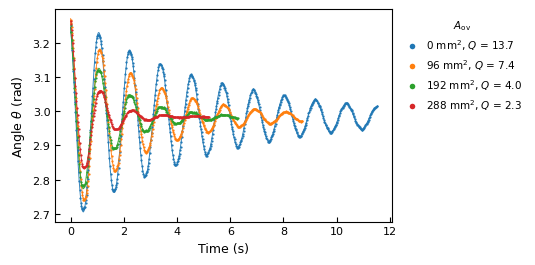

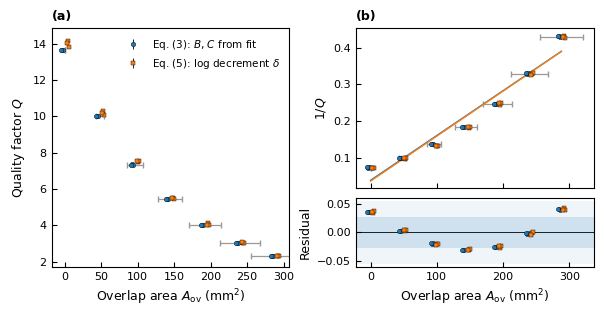

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

# =====================  USER INPUTS  =====================
data_file = 'lab5data_angles_trimmed.csv'   # trimmed angle data (time/angle column pairs)
n_pre = 5                                   # pre-release samples kept in the trimmed file (not fitted)

# Repeated runs sharing one knob position: (runs, knob turns)
groups = [((1, 2, 3), 0), ((4, 5, 6), 1), ((7, 8, 9), 2), ((10, 11, 12), 3),
          ((13, 14, 15), 2.5), ((16, 17, 18), 1.5), ((19, 20, 21), 0.5)] # Add this back in for the extra 0 measurement ((33,), 0)

# Geometry (mm) and measurement uncertainties
w, s_w = 18.0, 1                 # pole-face width
L, s_L, n_full = 10.0, 1, 15     # travel of l over n_full knob turns
n_mag = 8                          # A_ov = n_mag * w * l
per_turn, s_per_turn = L / n_full, s_L / n_full   # 2/3 mm and 0.5/15 mm per turn (turn count is exact)

# Method 2 (log decrement) settings
N_cycles = 1                       # cycles between the two amplitudes in Eq. (4)
amp_min = 0.02                     # rad: ignore amplitudes below this (too close to the noise floor)
prominence, half_window, min_separation = 0.01, 5, 0.5   # peak finding (rad, samples, s)

x_label = r'Overlap area $A_{\mathrm{ov}}$ (mm$^2$)'
fit_exclude_runs = ()              # e.g. (33,) to leave a run out of the Eq. (7) fits
fig1_runs = [1, 4, 7, 10]          # Figure 1: A_ov = 0, 96, 192, 288 mm^2
# =========================================================

def A_and_error(turns):
    l, s_l = turns * per_turn, turns * s_per_turn
    A = n_mag * w * l
    sA = n_mag * np.hypot(l * s_w, w * s_l)       # first-order propagation of s_w and s_l
    return A, sA

plt.rcParams.update({'font.size': 8, 'axes.labelsize': 9, 'legend.fontsize': 7.5,
                     'xtick.direction': 'in', 'ytick.direction': 'in', 'axes.linewidth': 0.8})
df = pd.read_csv(data_file)

def model(t, th_off, A, B, C, phi):                # Eq. (1)
    return th_off + A * np.exp(-B * t) * np.cos(C * t + phi)

def load_run(run):
    d = df[[f'Time (s) Run #{run}', f'Angle (rad) Run #{run}']].dropna().iloc[n_pre:]
    return d.iloc[:, 0].to_numpy() - d.iloc[0, 0], d.iloc[:, 1].to_numpy()

# ---------------- Method 1: Eq. (3) with B, C from a fit of Eq. (1) ----------------
def fit_run(run):
    t, a = load_run(run)
    pk, _ = find_peaks(a, prominence=0.01, distance=25)
    C0 = 2 * np.pi / np.median(np.diff(t[pk])) if len(pk) > 2 else 5.4
    th0 = np.mean(a[-20:])
    best = None
    for B0 in (0.1, 0.2, 0.4, 0.7, 1.2):           # several starting decay rates; keep the best fit
        try:
            p, cov = curve_fit(model, t, a, p0=[th0, a[0] - th0, B0, C0, 0.0], maxfev=20000)
            rss = np.sum((a - model(t, *p))**2)
            if best is None or rss < best[0]:
                best = (rss, p, cov)
        except RuntimeError:
            pass
    return best[1], best[2], t, a

def Q_from_BC(B, C, cov_BC):
    root = np.sqrt(1 + C**2 / B**2)
    J = np.array([-C**2 / (2 * B**3 * root), C / (2 * B**2 * root)])   # dQ/dB, dQ/dC
    return 0.5 * root, np.sqrt(J @ cov_BC @ J)                          # includes cov(B, C)

# ---------------- Method 2: Eq. (5) with delta from successive peak amplitudes ----------------
def refined_extrema(t, a, sign):
    """Times/values of maxima (sign=+1) or minima (sign=-1), refined by a parabola fit around each."""
    idx, _ = find_peaks(sign * a, prominence=prominence,
                        distance=max(int(min_separation / np.median(np.diff(t))), 1))
    idx = idx[(idx >= half_window) & (idx < len(a) - half_window)]
    te, ae = [], []
    for i in idx:
        sl = slice(i - half_window, i + half_window + 1)
        c2, c1, c0 = np.polyfit(t[sl] - t[i], a[sl], 2)
        te.append(t[i] - c1 / (2 * c2)); ae.append(c0 - c1**2 / (4 * c2))
    return np.array(te), np.array(ae)

def Q_from_delta(delta):
    return 0.5 * np.sqrt(1 + (2 * np.pi / delta)**2)

def method2(run):
    t, a = load_run(run)
    tM, aM = refined_extrema(t, a, +1); tm, am = refined_extrema(t, a, -1)
    ae = np.concatenate([aM, am])[np.argsort(np.concatenate([tM, tm]))]
    amp = np.abs(np.diff(ae)) / 2                    # half peak-to-peak between neighbouring extrema (no theta_off needed)
    step = 2 * N_cycles                              # consecutive extrema are half a cycle apart
    d = np.array([np.log(amp[k] / amp[k + step]) / N_cycles for k in range(len(amp) - step)
                  if amp[k] > amp_min and amp[k + step] > amp_min])
    if len(d) == 0:
        return np.nan, np.nan, np.nan
    delta = d.mean()
    s_delta = d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else np.nan
    dQ = abs(Q_from_delta(delta + s_delta) - Q_from_delta(delta - s_delta)) / 2 if np.isfinite(s_delta) else np.nan
    return delta, Q_from_delta(delta), dQ

# ---------- every run: both methods, A_ov +/- sigma_A
rows = []
for g, (runs, turns) in enumerate(groups):
    A, sA = A_and_error(turns)
    for run in runs:
        p, cov, t, a = fit_run(run)
        Q1, sQ1 = Q_from_BC(p[2], p[3], cov[2:4, 2:4])
        delta, Q2, sQ2 = method2(run)
        rows.append(dict(group=g, run=run, turns=turns, B=p[2], C=p[3], Q1=Q1, sQ1=sQ1,
                         delta=delta, Q2=Q2, sQ2=sQ2, x=A, sx=sA))
res = pd.DataFrame(rows)
for m in ('1', '2'):
    res[f'invQ{m}'] = 1 / res[f'Q{m}']
    res[f's_invQ{m}'] = res[f'sQ{m}'] / res[f'Q{m}']**2
res.to_csv('lab5_Q_per_run.csv', index=False)

# =====================  FIGURE 1: representative ring-downs  =====================
fig, ax = plt.subplots(figsize=(5.4, 2.7))
for i, run in enumerate(fig1_runs):
    p, cov, t, a = fit_run(run)
    Q, A = res.loc[res.run == run, ['Q1', 'x']].iloc[0]
    c = f'C{i}'
    ax.plot(t, model(t, *p), '-', color=c, lw=0.7, alpha=0.9, zorder=1)                      # fit under the data
    ax.plot(t, a, 'o', color=c, ms=1.6, mew=0, zorder=2, label=f'{A:.0f} mm$^2$, $Q$ = {Q:.1f}')  # raw data on top
ax.set_xlabel('Time (s)'); ax.set_ylabel(r'Angle $\theta$ (rad)')
ax.legend(frameon=False, bbox_to_anchor=(1.0, 1.0), handletextpad=0.3, markerscale=2.5, title=r'$A_{\mathrm{ov}}$', title_fontsize=7.5)
fig.tight_layout()
fig.savefig('fig1_ringdowns.pdf'); fig.savefig('fig1_ringdowns.png', dpi=300)

# =====================  FIGURE 2: Q vs overlap (both methods), 1/Q fits, residuals  =====================
# Empirical model of Eq. (7): 1/Q = 1/Q0 + k * A_ov, unweighted least squares on individual runs, per method
style = {'1': dict(fmt='o', color='C0', label=r'Eq. (3): $B$, $C$ from fit', dx=-4.0),
         '2': dict(fmt='s', color='C1', label=r'Eq. (5): log decrement $\delta$', dx=+4.0)}
fits = {}
for m in ('1', '2'):
    ok = res[f'invQ{m}'].notna() & ~res.run.isin(fit_exclude_runs)
    coef, cov_lin = np.polyfit(res.x[ok], res[f'invQ{m}'][ok], 1, cov=True)
    res[f'resid{m}'] = res[f'invQ{m}'] - np.polyval(coef, res.x)
    sigma = res.loc[ok, f'resid{m}'].std(ddof=2)
    fits[m] = (coef, sigma)
    print(f'Method {m}: 1/Q = ({coef[1]:.4f} +/- {np.sqrt(cov_lin[1,1]):.4f}) + ({coef[0]:.5f} +/- {np.sqrt(cov_lin[0,0]):.5f}) A_ov'
          f'   residual std = {sigma:.4f}')

fig = plt.figure(figsize=(7.0, 3.1))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.3], hspace=0.08, wspace=0.28)
axA = fig.add_subplot(gs[:, 0]); axB = fig.add_subplot(gs[0, 1]); axR = fig.add_subplot(gs[1, 1], sharex=axB)

def jit(run):                                      # small horizontal offset so repeats do not overlap
    return 0.0 if run == 33 else (run % 3 - 1) * 1.5

for ax, key in ((axA, 'Q'), (axB, 'invQ')):
    for m, s in style.items():
        for _, r in res.iterrows():
            ax.errorbar(r.x + s['dx'] + jit(r.run), r[f'{key}{m}'], yerr=r[f's_{key}{m}' if key == 'invQ' else f'sQ{m}'],
                        fmt=s['fmt'], ms=3.2, color=s['color'], mec='k', mew=0.3, ecolor='k', elinewidth=0.6, capsize=0,
                        label=s['label'] if (ax is axA and r.name == 0) else None)
    gm = res.groupby('group').agg(x=('x', 'first'), sx=('sx', 'first'), y=(f'{key}1', 'mean'))
    ax.errorbar(gm.x, gm.y, xerr=gm.sx, fmt='none', ecolor='0.6', elinewidth=0.9, capsize=2, zorder=0)  # ±σ(A_ov)
axA.set_ylabel(r'Quality factor $Q$'); axA.set_xlabel(x_label); axA.set_xlim(-18, 308)
axA.legend(frameon=False, loc='upper right')

xx = np.linspace(0, res.x.max(), 100)
for m, s in style.items():
    axB.plot(xx, np.polyval(fits[m][0], xx), '-', color=s['color'], lw=1.0)
axB.set_ylabel(r'$1/Q$'); plt.setp(axB.get_xticklabels(), visible=False)

axR.axhline(0, color='k', lw=0.6)
sig1 = fits['1'][1]
axR.axhspan(-sig1, sig1, color='C0', alpha=0.15, lw=0)                         # ±1 std of the Eq. (3) residuals
axR.axhspan(-2 * sig1, 2 * sig1, color='C0', alpha=0.07, lw=0)                 # ±2 std
for m, s in style.items():
    axR.plot(res.x + s['dx'] + res.run.map(jit), res[f'resid{m}'], s['fmt'], ms=3, color=s['color'], mec='k', mew=0.3)
axR.set_ylabel('Residual'); axR.set_xlabel(x_label)
for a_, lab in ((axA, '(a)'), (axB, '(b)')):
    a_.set_title(lab, loc='left', fontweight='bold', fontsize=9)
fig.savefig('fig2_Q_vs_overlap.pdf', bbox_inches='tight'); fig.savefig('fig2_Q_vs_overlap.png', dpi=300, bbox_inches='tight')
plt.show()

Method 1 | linear: 1/Q = (0.0383 ± 0.0212) + (0.00122 ± 0.00012) A, resid std 0.0311 | power: 1/Q0 = 0.0794 ± 0.0045, p = 1.74 ± 0.08, resid std 0.0056
Method 2 | linear: 1/Q = (0.0360 ± 0.0213) + (0.00123 ± 0.00012) A, resid std 0.0313 | power: 1/Q0 = 0.0774 ± 0.0042, p = 1.74 ± 0.07, resid std 0.0052


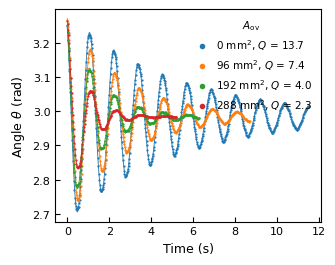

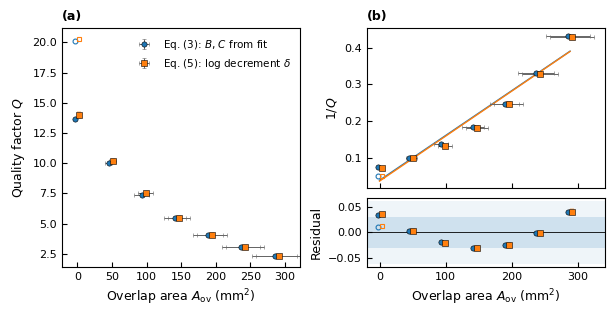

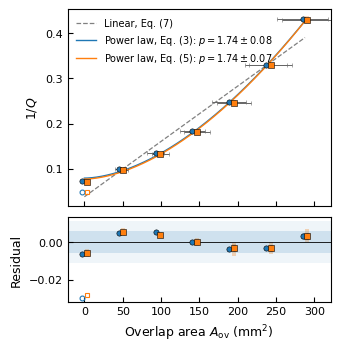

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

# =====================  USER INPUTS  =====================
data_file = 'lab5data_angles_trimmed.csv'   # trimmed angle data (time/angle column pairs)
n_pre = 5                                   # pre-release samples kept in the trimmed file (not fitted)

# Repeated runs sharing one knob position: (runs, knob turns)
groups = [((1, 2, 3), 0), ((4, 5, 6), 1), ((7, 8, 9), 2), ((10, 11, 12), 3),
          ((13, 14, 15), 2.5), ((16, 17, 18), 1.5), ((19, 20, 21), 0.5)] # Add this back for extra 0 run , ((33,), 0)

# Geometry (mm) and measurement uncertainties
w, s_w = 18.0, 1.0                 # pole-face width
L, s_L, n_full = 10.0, 1.0, 15     # travel of l over n_full knob turns
n_mag = 8                          # A_ov = n_mag * w * l
per_turn, s_per_turn = L / n_full, s_L / n_full   # 2/3 mm and 0.5/15 mm per turn (turn count is exact)

# Method 2 (log decrement) settings
N_cycles = 1                       # cycles between the two amplitudes in Eq. (4)
amp_min = 0.02                     # rad: ignore amplitudes below this (too close to the noise floor)
prominence, half_window, min_separation = 0.01, 5, 0.5   # peak finding (rad, samples, s)

x_label = r'Overlap area $A_{\mathrm{ov}}$ (mm$^2$)'
fit_exclude_runs = (33,)           # runs left out of all fits (plotted as open markers): zero position uncertain
fig1_runs = [1, 4, 7, 10]          # Figure 1: A_ov = 0, 96, 192, 288 mm^2
# =========================================================

def A_and_error(turns):
    l, s_l = turns * per_turn, turns * s_per_turn
    A = n_mag * w * l
    sA = n_mag * np.hypot(l * s_w, w * s_l)       # first-order propagation of s_w and s_l
    return A, sA

plt.rcParams.update({'font.size': 8, 'axes.labelsize': 9, 'legend.fontsize': 7.5,
                     'xtick.direction': 'in', 'ytick.direction': 'in', 'axes.linewidth': 0.8})
df = pd.read_csv(data_file)

def model(t, th_off, A, B, C, phi):                # Eq. (1)
    return th_off + A * np.exp(-B * t) * np.cos(C * t + phi)

def load_run(run):
    d = df[[f'Time (s) Run #{run}', f'Angle (rad) Run #{run}']].dropna().iloc[n_pre:]
    return d.iloc[:, 0].to_numpy() - d.iloc[0, 0], d.iloc[:, 1].to_numpy()

# ---------------- Method 1: Eq. (3) with B, C from a fit of Eq. (1) ----------------
def fit_run(run):
    t, a = load_run(run)
    pk, _ = find_peaks(a, prominence=0.01, distance=25)
    C0 = 2 * np.pi / np.median(np.diff(t[pk])) if len(pk) > 2 else 5.4
    th0 = np.mean(a[-20:])
    best = None
    for B0 in (0.1, 0.2, 0.4, 0.7, 1.2):           # several starting decay rates; keep the best fit
        try:
            p, cov = curve_fit(model, t, a, p0=[th0, a[0] - th0, B0, C0, 0.0], maxfev=20000)
            rss = np.sum((a - model(t, *p))**2)
            if best is None or rss < best[0]:
                best = (rss, p, cov)
        except RuntimeError:
            pass
    return best[1], best[2], t, a

def Q_from_BC(B, C, cov_BC):
    root = np.sqrt(1 + C**2 / B**2)
    J = np.array([-C**2 / (2 * B**3 * root), C / (2 * B**2 * root)])   # dQ/dB, dQ/dC
    return 0.5 * root, np.sqrt(J @ cov_BC @ J)                          # includes cov(B, C)

# ---------------- Method 2: Eq. (5) with delta from successive peak amplitudes ----------------
def refined_extrema(t, a, sign):
    """Times/values of maxima (sign=+1) or minima (sign=-1), refined by a parabola fit around each."""
    idx, _ = find_peaks(sign * a, prominence=prominence,
                        distance=max(int(min_separation / np.median(np.diff(t))), 1))
    idx = idx[(idx >= half_window) & (idx < len(a) - half_window)]
    te, ae = [], []
    for i in idx:
        sl = slice(i - half_window, i + half_window + 1)
        c2, c1, c0 = np.polyfit(t[sl] - t[i], a[sl], 2)
        te.append(t[i] - c1 / (2 * c2)); ae.append(c0 - c1**2 / (4 * c2))
    return np.array(te), np.array(ae)

def Q_from_delta(delta):
    return 0.5 * np.sqrt(1 + (2 * np.pi / delta)**2)

def method2(run):
    t, a = load_run(run)
    tM, aM = refined_extrema(t, a, +1); tm, am = refined_extrema(t, a, -1)
    ae = np.concatenate([aM, am])[np.argsort(np.concatenate([tM, tm]))]
    amp = np.abs(np.diff(ae)) / 2                    # half peak-to-peak between neighbouring extrema (no theta_off needed)
    step = 2 * N_cycles                              # consecutive extrema are half a cycle apart
    d = np.array([np.log(amp[k] / amp[k + step]) / N_cycles for k in range(len(amp) - step)
                  if amp[k] > amp_min and amp[k + step] > amp_min])
    if len(d) == 0:
        return np.nan, np.nan, np.nan
    delta = d.mean()
    s_delta = d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else np.nan
    dQ = abs(Q_from_delta(delta + s_delta) - Q_from_delta(delta - s_delta)) / 2 if np.isfinite(s_delta) else np.nan
    return delta, Q_from_delta(delta), dQ

# ---------- every run: both methods, A_ov +/- sigma_A
rows = []
for g, (runs, turns) in enumerate(groups):
    A, sA = A_and_error(turns)
    for run in runs:
        p, cov, t, a = fit_run(run)
        Q1, sQ1 = Q_from_BC(p[2], p[3], cov[2:4, 2:4])
        delta, Q2, sQ2 = method2(run)
        rows.append(dict(group=g, run=run, turns=turns, B=p[2], C=p[3], Q1=Q1, sQ1=sQ1,
                         delta=delta, Q2=Q2, sQ2=sQ2, x=A, sx=sA))
res = pd.DataFrame(rows)
for m in ('1', '2'):
    res[f'invQ{m}'] = 1 / res[f'Q{m}']
    res[f's_invQ{m}'] = res[f'sQ{m}'] / res[f'Q{m}']**2
res.to_csv('lab5_Q_per_run.csv', index=False)

# =====================  FIGURE 1: representative ring-downs  =====================
fig, ax = plt.subplots(figsize=(3.4, 2.7))
for i, run in enumerate(fig1_runs):
    p, cov, t, a = fit_run(run)
    Q, A = res.loc[res.run == run, ['Q1', 'x']].iloc[0]
    c = f'C{i}'
    ax.plot(t, model(t, *p), '-', color=c, lw=0.7, alpha=0.9, zorder=1)                      # fit under the data
    ax.plot(t, a, 'o', color=c, ms=1.6, mew=0, zorder=2, label=f'{A:.0f} mm$^2$, $Q$ = {Q:.1f}')  # raw data on top
ax.set_xlabel('Time (s)'); ax.set_ylabel(r'Angle $\theta$ (rad)')
ax.legend(frameon=False, loc='upper right', handletextpad=0.3, markerscale=2.5, title=r'$A_{\mathrm{ov}}$', title_fontsize=7.5)
fig.tight_layout()
fig.savefig('fig1_ringdowns.pdf'); fig.savefig('fig1_ringdowns.png', dpi=300)

# =====================  GROUP MEANS  =====================
# Mean of the repeats at each knob position. Error bar = quadrature sum of
#   (i)  the standard error of the repeats, s/sqrt(n), and
#   (ii) the propagated extraction error of the mean, sqrt(sum sigma_i^2)/n.
excl = res.run.isin(fit_exclude_runs)
def group_means(m):
    out = []
    for g, d in res[~excl].groupby('group'):
        n, Q = len(d), d[f'Q{m}'].mean()
        sem = d[f'Q{m}'].std(ddof=1) / np.sqrt(n) if n > 1 else 0.0
        prop = np.sqrt(np.nansum(d[f'sQ{m}']**2)) / n          # runs without a propagated error contribute 0
        sQ = np.hypot(sem, prop)
        out.append(dict(group=g, x=d.x.iloc[0], sx=d.sx.iloc[0], n=n, Q=Q, sQ=sQ, sem=sem, prop=prop,
                        invQ=1 / Q, s_invQ=sQ / Q**2))
    return pd.DataFrame(out).sort_values('x').reset_index(drop=True)
means = {m: group_means(m) for m in ('1', '2')}
pd.concat([means[m].assign(method=m) for m in means]).to_csv('lab5_Q_group_means.csv', index=False)

style = {'1': dict(fmt='o', color='C0', label=r'Eq. (3): $B$, $C$ from fit', dx=-3.0),
         '2': dict(fmt='s', color='C1', label=r'Eq. (5): log decrement $\delta$', dx=+3.0)}

def draw_points(ax, key, resid=None):
    """Faint individual runs, group means with error bars, run 33 as open markers."""
    for m, s in style.items():
        yi = res[f'{key}{m}'] if resid is None else res[f'{resid}{m}']
        ax.plot(res.x[~excl] + s['dx'], yi[~excl], s['fmt'], ms=2.2, color=s['color'], alpha=0.3, mew=0, zorder=1)
        ax.plot(res.x[excl] + s['dx'], yi[excl], s['fmt'], ms=3.5, mfc='none', mec=s['color'], mew=0.8, zorder=3)
        g = means[m]
        y = g[key] if resid is None else g[f'{resid}']
        yerr = g[f's_{key}'] if key == 'invQ' else g['sQ']
        ax.errorbar(g.x + s['dx'], y, yerr=yerr, xerr=g.sx if resid is None else None, fmt=s['fmt'], ms=3.8,
                    color=s['color'], mec='k', mew=0.4, ecolor='0.4', elinewidth=0.7, capsize=1.5, zorder=2,
                    label=s['label'] if (resid is None and key == 'Q') else None)

# ---------- fits on the 7 group means (unweighted; run 33 excluded)
def power(A, a, k, p):
    return a + k * A**p                                     # p = 1 recovers Eq. (7)
fits_lin, fits_pl = {}, {}
for m in ('1', '2'):
    g = means[m]
    c, cv = np.polyfit(g.x, g.invQ, 1, cov=True)
    g['resid_lin'] = g.invQ - np.polyval(c, g.x)
    res[f'resid_lin{m}'] = res[f'invQ{m}'] - np.polyval(c, res.x)
    fits_lin[m] = (c, np.sqrt(np.diag(cv)), g.resid_lin.std(ddof=2))
    p, pc = curve_fit(power, g.x, g.invQ, p0=[0.07, 1e-5, 1.5], maxfev=20000)
    g['resid_pl'] = g.invQ - power(g.x, *p)
    res[f'resid_pl{m}'] = res[f'invQ{m}'] - power(res.x, *p)
    fits_pl[m] = (p, np.sqrt(np.diag(pc)), g.resid_pl.std(ddof=3))
    cl, el, sl = fits_lin[m]; pp, ep, sp = fits_pl[m]
    print(f'Method {m} | linear: 1/Q = ({cl[1]:.4f} ± {el[1]:.4f}) + ({cl[0]:.5f} ± {el[0]:.5f}) A, resid std {sl:.4f}'
          f' | power: 1/Q0 = {pp[0]:.4f} ± {ep[0]:.4f}, p = {pp[2]:.2f} ± {ep[2]:.2f}, resid std {sp:.4f}')

xx = np.linspace(0, res.x.max(), 200)

# =====================  FIGURE 2: Q vs overlap, linear 1/Q fit, residuals  =====================
fig = plt.figure(figsize=(7.0, 3.1))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.3], hspace=0.08, wspace=0.28)
axA = fig.add_subplot(gs[:, 0]); axB = fig.add_subplot(gs[0, 1]); axR = fig.add_subplot(gs[1, 1], sharex=axB)
draw_points(axA, 'Q'); draw_points(axB, 'invQ'); draw_points(axR, 'invQ', resid='resid_lin')
axA.set_ylabel(r'Quality factor $Q$'); axA.set_xlabel(x_label); axA.set_xlim(-22, 322)
axA.legend(frameon=False, loc='upper right')
for m, s in style.items():
    axB.plot(xx, np.polyval(fits_lin[m][0], xx), '-', color=s['color'], lw=1.0, zorder=0)
axB.set_ylabel(r'$1/Q$'); plt.setp(axB.get_xticklabels(), visible=False)
sig = fits_lin['1'][2]
axR.axhline(0, color='k', lw=0.6)
axR.axhspan(-sig, sig, color='C0', alpha=0.15, lw=0); axR.axhspan(-2*sig, 2*sig, color='C0', alpha=0.07, lw=0)
axR.set_ylabel('Residual'); axR.set_xlabel(x_label)
for a_, lab in ((axA, '(a)'), (axB, '(b)')):
    a_.set_title(lab, loc='left', fontweight='bold', fontsize=9)
fig.savefig('fig2_Q_vs_overlap.pdf', bbox_inches='tight'); fig.savefig('fig2_Q_vs_overlap.png', dpi=300, bbox_inches='tight')

# =====================  FIGURE 3: power-law model 1/Q = 1/Q0 + k A^p  =====================
fig = plt.figure(figsize=(3.4, 3.8))
gs = fig.add_gridspec(2, 1, height_ratios=[3, 1.3], hspace=0.08)
axT = fig.add_subplot(gs[0]); axR = fig.add_subplot(gs[1], sharex=axT)
draw_points(axT, 'invQ'); draw_points(axR, 'invQ', resid='resid_pl')
axT.plot(xx, np.polyval(fits_lin['1'][0], xx), '--', color='0.5', lw=0.9, zorder=0, label='Linear, Eq. (7)')
for m, s in style.items():
    axT.plot(xx, power(xx, *fits_pl[m][0]), '-', color=s['color'], lw=1.0, zorder=0,
             label=rf'Power law, Eq. ({"3" if m == "1" else "5"}): $p = {fits_pl[m][0][2]:.2f} \pm {fits_pl[m][1][2]:.2f}$')
axT.set_ylabel(r'$1/Q$'); plt.setp(axT.get_xticklabels(), visible=False)
axT.legend(frameon=False, loc='upper left', fontsize=7)
sig = fits_pl['1'][2]
axR.axhline(0, color='k', lw=0.6)
axR.axhspan(-sig, sig, color='C0', alpha=0.15, lw=0); axR.axhspan(-2*sig, 2*sig, color='C0', alpha=0.07, lw=0)
axR.set_ylabel('Residual'); axR.set_xlabel(x_label); axR.set_xlim(-22, 322)
fig.savefig('fig3_powerlaw.pdf', bbox_inches='tight'); fig.savefig('fig3_powerlaw.png', dpi=300, bbox_inches='tight')
plt.show()